## Section 1: Introduction and dataset selection ##

# Image Recognition Using Convolutional Neural Networks (CNNs)

## Portfolio of Evidence

This project investigates the use of Convolutional Neural Networks (CNNs) for image recognition. The MNIST handwritten digits dataset is used to explore image patterns, prepare image data, develop CNN models, and evaluate their classification performance.

The project also considers how image recognition techniques could be extended to future applications such as facial recognition.

## 1. Introduction and Project Objectives

The purpose of this project is to develop an image classification system using a Convolutional Neural Network (CNN).

The main objectives are to:
- Examine and justify the selected image dataset.
- Perform exploratory data analysis (EDA).
- Prepare image data for CNN training.
- Investigate image features and patterns.
- Develop and train CNN models.
- Evaluate and compare model performance.
- Discuss limitations and future applications.

## 2. Dataset Selection and Suitability

The MNIST dataset was selected for this project. It contains 70,000 grayscale images of handwritten digits from 0 to 9. Each image has dimensions of 28 × 28 pixels.

The dataset is suitable for demonstrating CNN-based image recognition because it contains labelled images, consistent dimensions, and ten clearly defined classes.

MNIST is a benchmark dataset, making it useful for developing and evaluating image classification models.

### Dataset Limitations and Considerations

Although MNIST is suitable for handwritten digit recognition, it does not contain photographs of human faces. Therefore, the model developed in this project cannot identify people.

A future facial recognition system would require an appropriate facial image dataset, consent from individuals, privacy protection, secure data storage, and testing for bias and differences in lighting, pose, and image quality.

### Dataset Quality

The dataset will be examined for:
- Missing or invalid pixel values.
- Image dimensions and data types.
- Valid class labels.
- Class distribution and possible imbalance.
- Pixel intensity ranges.

These checks help establish whether the dataset is suitable for reliable model training.

## Section 2: Import libraries and load the dataset

## 3. Importing Libraries

The following Python libraries will be used for data analysis, visualisation, preprocessing, CNN development, and model evaluation.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import warnings
warnings.filterwarnings("ignore")

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0
NumPy version: 2.2.6
Pandas version: 2.3.3


## 4. Loading the MNIST Dataset

The MNIST dataset is available directly through Keras. It is already divided into training and testing sets.

The training set contains 60,000 images, while the test set contains 10,000 images.

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Dataset loaded successfully!")
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


### Understanding the Dataset Structure

Each image is represented as a 28 × 28 numerical array. The corresponding label identifies the handwritten digit represented by that image.

The labels range from 0 to 9, giving the classification problem ten possible output classes.

In [4]:
print("Total training images:", len(x_train))
print("Total testing images:", len(x_test))
print("Total images:", len(x_train) + len(x_test))

print("\nImage dimensions:", x_train.shape[1:])
print("Number of classes:", len(np.unique(y_train)))
print("Training image data type:", x_train.dtype)
print("Training label data type:", y_train.dtype)

print("\nUnique digit labels:")
print(np.unique(y_train))

Total training images: 60000
Total testing images: 10000
Total images: 70000

Image dimensions: (28, 28)
Number of classes: 10
Training image data type: uint8
Training label data type: uint8

Unique digit labels:
[0 1 2 3 4 5 6 7 8 9]


### Initial Dataset Quality Checks

The dataset will be checked for missing values, invalid numerical values, unexpected image dimensions, and labels outside the expected range.

In [5]:
print("Missing values in training images:",
      np.isnan(x_train).sum())

print("Missing values in testing images:",
      np.isnan(x_test).sum())

print("Invalid numerical values in training images:",
      np.isfinite(x_train).all() == False)

print("Invalid numerical values in testing images:",
      np.isfinite(x_test).all() == False)

print("\nTraining pixel range:",
      x_train.min(), "to", x_train.max())

print("Testing pixel range:",
      x_test.min(), "to", x_test.max())

print("\nAll training images have correct dimensions:",
      x_train.shape[1:] == (28, 28))

print("All testing images have correct dimensions:",
      x_test.shape[1:] == (28, 28))

print("All training labels are valid:",
      np.isin(y_train, range(10)).all())

print("All testing labels are valid:",
      np.isin(y_test, range(10)).all())

Missing values in training images: 0
Missing values in testing images: 0
Invalid numerical values in training images: False
Invalid numerical values in testing images: False

Training pixel range: 0 to 255
Testing pixel range: 0 to 255

All training images have correct dimensions: True
All testing images have correct dimensions: True
All training labels are valid: True
All testing labels are valid: True


### Dataset Quality Interpretation

The checks help determine whether the images and labels are suitable for training. MNIST is expected to contain valid 28 × 28 grayscale images, pixel values between 0 and 255, and labels from 0 to 9.

The results will be used to identify any preprocessing requirements before model development.

## Section 3: Analysis planning
## 5. Analysis Plan

The project follows a structured machine learning workflow:

1. Load and inspect the dataset.
2. Perform exploratory data analysis.
3. Examine image quality and class distribution.
4. Normalise and reshape the images.
5. Divide the training data into training and validation sets.
6. Investigate image features.
7. Develop a baseline CNN.
8. Develop an improved CNN.
9. Compare models using validation performance.
10. Evaluate the selected model on the test dataset.
11. Interpret the results and provide recommendations.

### Research Questions

The analysis will address the following questions:

- Is the MNIST dataset suitable for CNN-based image recognition?
- Are the ten digit classes adequately represented?
- What visual patterns can be observed in the images?
- Can a CNN accurately classify handwritten digits?
- Does an improved CNN produce better validation performance?
- Which digit classes are most frequently misclassified?

### Model Development Plan

Two CNN models will be developed.

**Baseline model:** Uses convolutional layers, max pooling, and dense layers to establish an initial classification performance.

**Improved model:** Introduces data augmentation, additional dense-layer capacity, and dropout to investigate whether these techniques improve generalisation.

The Adam optimiser and sparse categorical cross-entropy loss function will be used because the task involves ten mutually exclusive classes represented by integer labels.

### Evaluation Plan

The models will be evaluated using:

- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of predicted class instances that are correct.
- Recall: Proportion of actual class instances correctly identified.
- F1-score: Balance between precision and recall.
- Confusion matrix: Shows correct and incorrect predictions for each digit.
- Training and validation curves: Help identify overfitting and learning behaviour.

Validation performance will be used to select the model. The test set will be reserved for the final evaluation.

## Section 4: Exploratory Data Analysis (EDA)
## 6. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the structure, distribution, and visual characteristics of the image dataset before model training.

The analysis includes sample images, class distribution, average digit images, pixel intensity, and differences betw

### Visualising Sample Images

A sample of 15 images will be displayed with their corresponding labels. This helps examine the appearance and variation of handwritten digits.

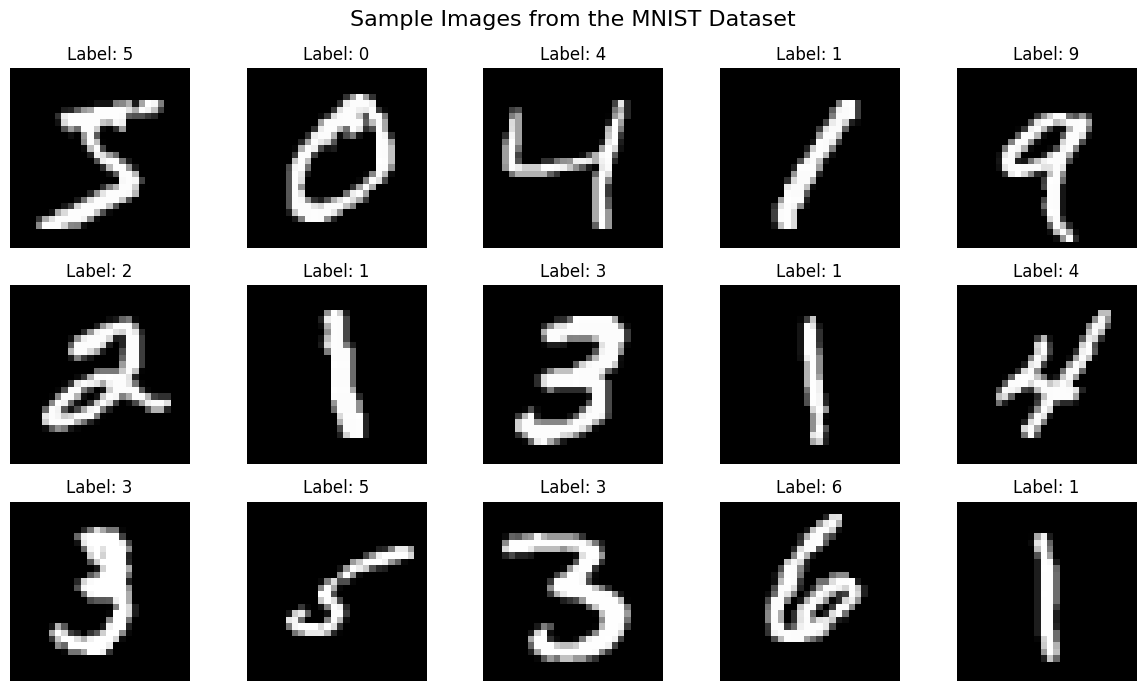

In [6]:
plt.figure(figsize=(12, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Images from the MNIST Dataset", fontsize=16)
plt.tight_layout()
plt.show()

**Sample Image Interpretation:**

The images show that handwritten digits can differ in thickness, shape, size, and writing style. Some digits may look similar, which can make classification challenging.

CNNs are appropriate because convolutional filters can learn local visual patterns such as edges, curves, and shapes.

### Class Distribution

The class distribution is examined to determine whether all ten digit categories are adequately represented in the training dataset.

,Digit,Image Count,Percentage
0,0,5923,9.87
1,1,6742,11.24
2,2,5958,9.93
3,3,6131,10.22
4,4,5842,9.74
5,5,5421,9.04
6,6,5918,9.86
7,7,6265,10.44
8,8,5851,9.75
9,9,5949,9.92


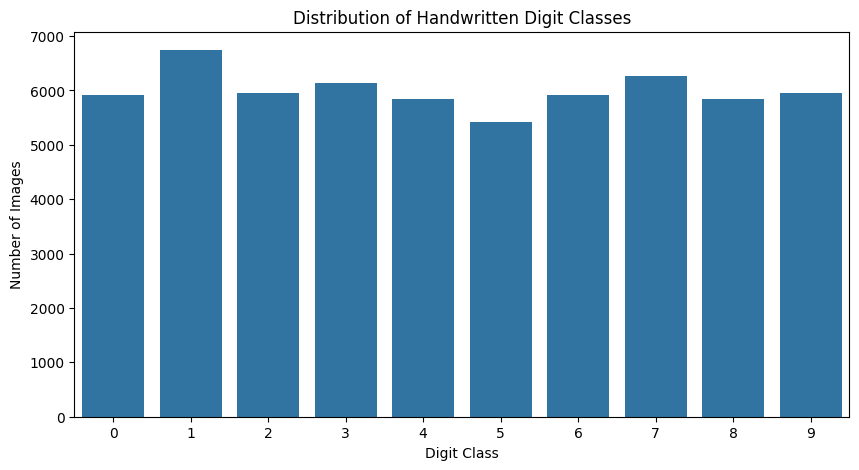

In [7]:
class_counts = pd.Series(y_train).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Digit": class_counts.index,
    "Image Count": class_counts.values,
    "Percentage": (class_counts.values / len(y_train)) * 100
})

display(class_distribution.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    x="Digit",
    y="Image Count",
    data=class_distribution
)

plt.title("Distribution of Handwritten Digit Classes")
plt.xlabel("Digit Class")
plt.ylabel("Number of Images")
plt.show()

**Class Distribution Interpretation:**

The class distribution indicates whether the dataset contains a reasonable number of examples for each digit.

If some classes contain substantially fewer images, the model may learn those classes less effectively. The distribution will therefore be considered when interpreting the classification results.

### Average Image per Digit

Average images are created by calculating the mean pixel intensity for every digit class. This provides a visual representation of the common patterns associated with each digit.

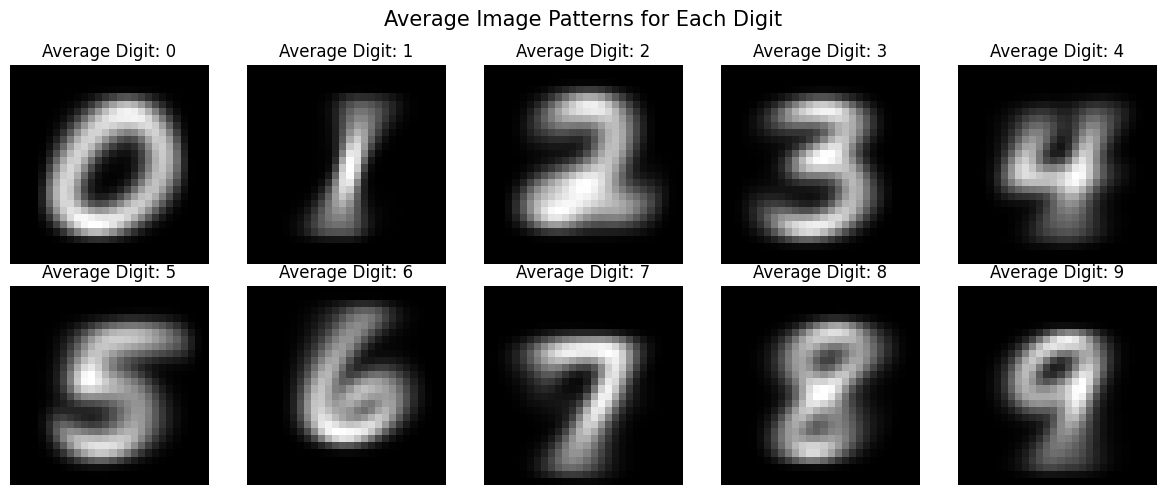

In [8]:
plt.figure(figsize=(12, 5))

for digit in range(10):
    digit_images = x_train[y_train == digit]
    average_image = digit_images.mean(axis=0)

    plt.subplot(2, 5, digit + 1)
    plt.imshow(average_image, cmap="gray")
    plt.title(f"Average Digit: {digit}")
    plt.axis("off")

plt.suptitle("Average Image Patterns for Each Digit", fontsize=15)
plt.tight_layout()
plt.show()

**Average Image Interpretation:**

The average images highlight the regions where pixels are most frequently activated for each digit.

Although individual handwriting varies, common structures can be observed. These recurring visual patterns may help CNN filters distinguish between different digit classes.

### Pixel Intensity Analysis

Grayscale images contain pixel values representing brightness. In MNIST, 0 represents black and 255 represents white.

Pixel intensity statistics are examined to understand the distribution of brightness values in the dataset.

Minimum pixel intensity: 0
Maximum pixel intensity: 255
Mean pixel intensity: 33.318421449829934
Standard deviation: 78.56748998339798


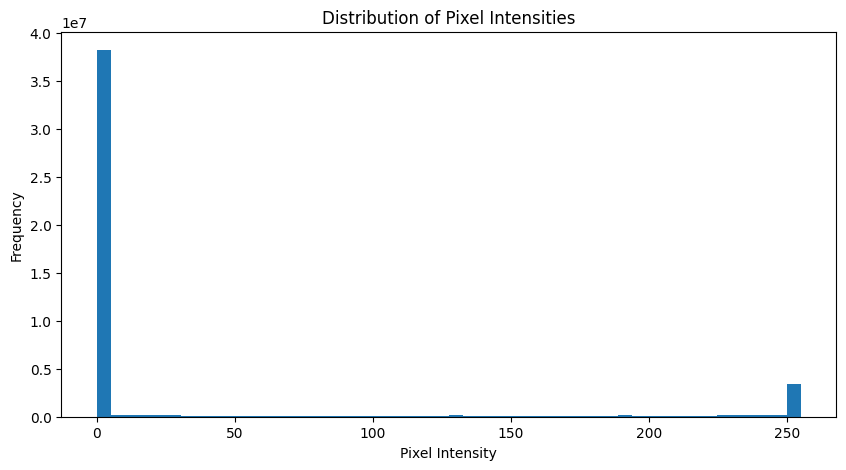

In [9]:
pixel_values = x_train.flatten()

print("Minimum pixel intensity:", pixel_values.min())
print("Maximum pixel intensity:", pixel_values.max())
print("Mean pixel intensity:", pixel_values.mean())
print("Standard deviation:", pixel_values.std())

plt.figure(figsize=(10, 5))
plt.hist(pixel_values, bins=50)
plt.title("Distribution of Pixel Intensities")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

**Pixel Intensity Interpretation:**

The pixel intensity distribution helps explain the visual structure of the images. Most pixels are expected to represent the dark background, while brighter values represent the handwritten digits.

Normalisation will convert these values to a range between 0 and 1, making them easier for the neural network to process.

### Comparing Different Digit Classes

One example from each digit class will be displayed to examine differences in shape and structure.

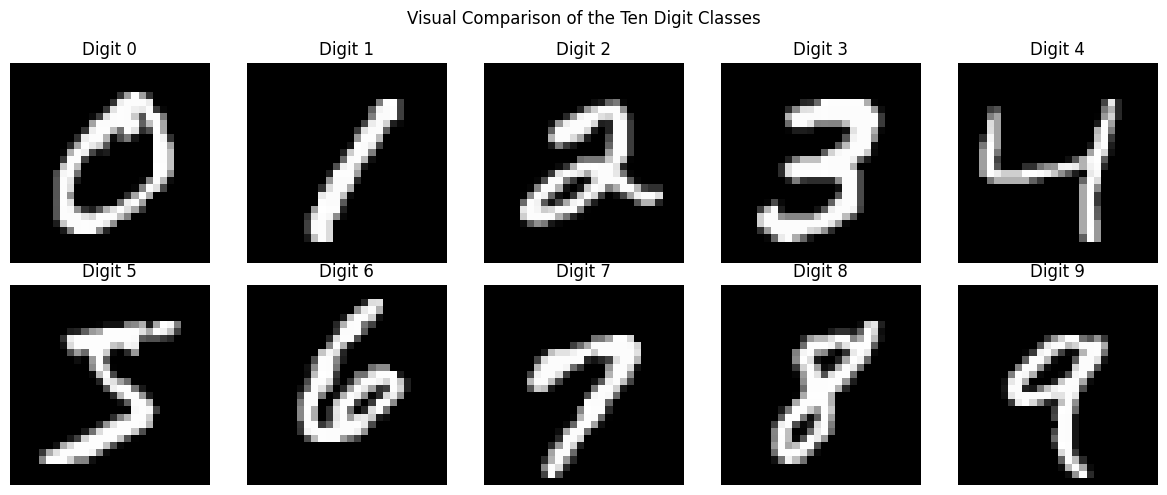

In [10]:
plt.figure(figsize=(12, 5))

for digit in range(10):
    index = np.where(y_train == digit)[0][0]

    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[index], cmap="gray")
    plt.title(f"Digit {digit}")
    plt.axis("off")

plt.suptitle("Visual Comparison of the Ten Digit Classes")
plt.tight_layout()
plt.show()

**Visual Comparison Interpretation:**

The digit classes have different visual structures, but some may share similar features. For example, handwritten digits can have variations in curves, loops, and stroke direction.

These similarities may cause classification errors. CNNs can learn combinations of visual features to distinguish between classes.

### Comparing Pixel Intensity Across Classes

The average pixel intensity of each digit class is calculated to investigate whether some classes generally contain thicker or more visually dense handwritten strokes.

,Digit,Mean Pixel Intensity
0,0,44.22
1,1,19.38
2,2,37.99
3,3,36.09
4,4,30.95
5,5,32.83
6,6,35.01
7,7,29.20
8,8,38.29
9,9,31.26


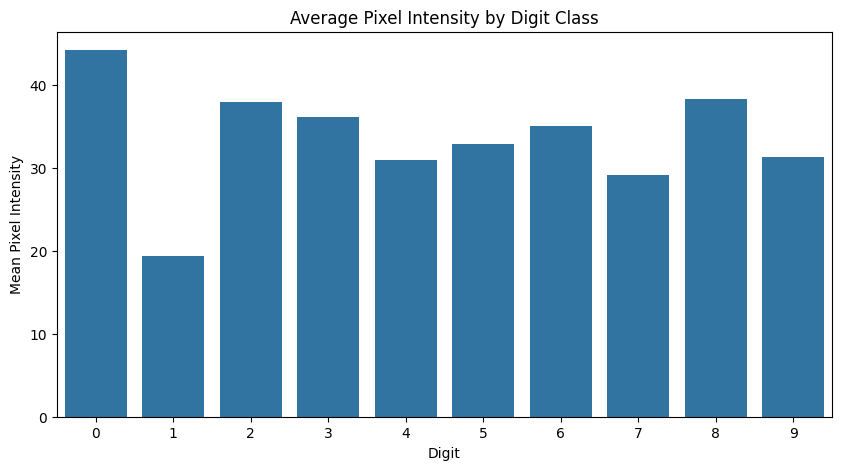

In [11]:
mean_intensity_by_digit = []

for digit in range(10):
    digit_images = x_train[y_train == digit]
    mean_intensity_by_digit.append(digit_images.mean())

intensity_table = pd.DataFrame({
    "Digit": range(10),
    "Mean Pixel Intensity": mean_intensity_by_digit
})

display(intensity_table.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    x="Digit",
    y="Mean Pixel Intensity",
    data=intensity_table
)

plt.title("Average Pixel Intensity by Digit Class")
plt.xlabel("Digit")
plt.ylabel("Mean Pixel Intensity")
plt.show()

**Class Intensity Interpretation:**

Differences in mean pixel intensity may reflect variations in the thickness and writing style of the digits. However, average intensity alone cannot reliably identify a digit.

The CNN will therefore learn more complex spatial features instead of relying on a single numerical measurement.

## Section 5: Data preprocessing
## 7. Data Preprocessing

Preprocessing prepares the images for CNN training. The pixel values will be normalised, and a channel dimension will

**Normalising Pixel Values**

The original pixel values range from 0 to 255. Dividing them by 255 converts the values to a range between 0 and 1.

This helps improve numerical stability and supports effective neural network training.

In [12]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training pixel range:",
      x_train.min(), "to", x_train.max())

print("Testing pixel range:",
      x_test.min(), "to", x_test.max())

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


**Reshaping the Images:**

A CNN expects grayscale images to have three dimensions: image height, image width, and number of channels.

A single channel is added to each image because MNIST contains grayscale rather than colour images.

In [13]:
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

print("Training CNN input shape:", x_train_cnn.shape)
print("Testing CNN input shape:", x_test_cnn.shape)

Training CNN input shape: (60000, 28, 28, 1)
Testing CNN input shape: (10000, 28, 28, 1)


**Creating Training and Validation Sets**

The original training dataset will be divided into training and validation sets.

The validation set will help assess model performance during training and support model selection. Stratified sampling is used to preserve the class distribution in both sets.

The test dataset remains separate and will only be used for the final evaluation.

In [14]:
x_train_final, x_val, y_train_final, y_val = train_test_split(
    x_train_cnn,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training set:", x_train_final.shape)
print("Validation set:", x_val.shape)
print("Testing set:", x_test_cnn.shape)

print("\nTraining labels:", y_train_final.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training set: (48000, 28, 28, 1)
Validation set: (12000, 28, 28, 1)
Testing set: (10000, 28, 28, 1)

Training labels: (48000,)
Validation labels: (12000,)
Testing labels: (10000,)


**Verifying the Data Split:**

The three datasets are checked to confirm that the training, validation, and testing images have the expected dimensions.

The training set is used to fit the models, the validation set is used to monitor performance and select a model, and the test set is reserved for final evaluation.

In [15]:
print("Training samples:", len(x_train_final))
print("Validation samples:", len(x_val))
print("Testing samples:", len(x_test_cnn))

print("\nTraining class distribution:")
print(pd.Series(y_train_final).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Training samples: 48000
Validation samples: 12000
Testing samples: 10000

Training class distribution:
0    4738
1    5394
2    4766
3    4905
4    4674
5    4337
6    4734
7    5012
8    4681
9    4759
Name: count, dtype: int64

Validation class distribution:
0    1185
1    1348
2    1192
3    1226
4    1168
5    1084
6    1184
7    1253
8    1170
9    1190
Name: count, dtype: int64


**Displaying Preprocessed Images**

A selection of normalised images is displayed to confirm that preprocessing has preserved the original digit patterns.

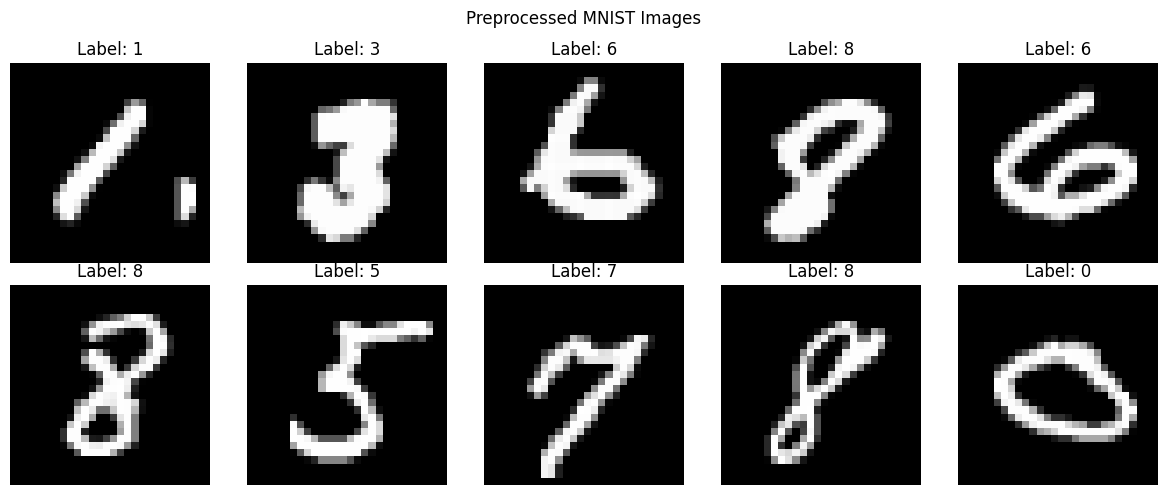

In [16]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_final[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train_final[i]}")
    plt.axis("off")

plt.suptitle("Preprocessed MNIST Images")
plt.tight_layout()
plt.show()

**Preprocessing Interpretation:**

Normalisation converts the pixel values into a consistent numerical range, while reshaping provides the input structure required by CNN layers.

The stratified split preserves class representation across the training and validation sets. These steps prepare the dataset for model development.

## Section 6: Image features and feature extraction
## 8. Image Features and Feature Extraction

Images contain spatial information that can be represented through pixel values. CNNs learn useful visual features automatically through convolutional filters.

This section examines the pixel structure of an image before investigating the features learned by the trained CN

**Visualising Pixel Values:**

A single digit is displayed together with its numerical pixel values. This demonstrates how a handwritten image is represented in a computer.

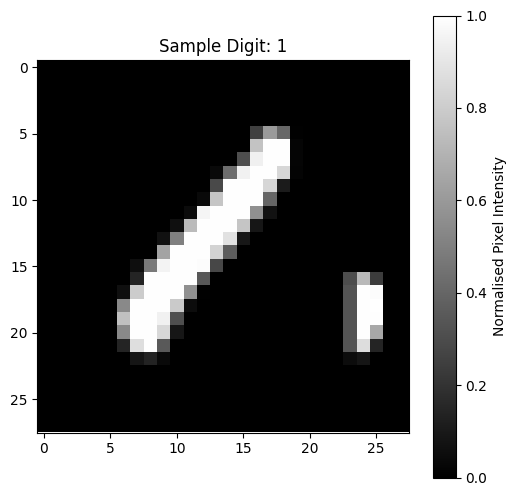

Pixel values of the sample image:
[[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.25 0.6  0.4  0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.77 1.   1.   0.02 0.   0

In [17]:
sample_index = 0

sample_image = x_train_final[sample_index].squeeze()

plt.figure(figsize=(6, 6))
plt.imshow(sample_image, cmap="gray")
plt.title(f"Sample Digit: {y_train_final[sample_index]}")
plt.colorbar(label="Normalised Pixel Intensity")
plt.show()

print("Pixel values of the sample image:")
print(np.round(sample_image, 2))

**Pixel Feature Interpretation:**

Each image is represented by a matrix of numerical pixel intensities. These values contain the information needed to identify the handwritten digit.

However, individual pixels do not provide enough information on their own. CNNs learn relationships between neighbouring pixels to identify meaningful visual patterns.

## Section 7: CNN model development
## 9. Developing the Baseline CNN Model

A baseline CNN will be developed to establish an initial performance level.

The architecture uses convolutional layers to detect image features, max-pooling layers to reduce spatial dimensions

### Baseline CNN Architecture

The model consists of:

- Input layer: Accepts 28 × 28 grayscale images.
- First convolutional layer: Learns basic patterns using 32 filters.
- First max-pooling layer: Reduces feature-map dimensions.
- Second convolutional layer: Learns more complex patterns using 64 filters.
- Second max-pooling layer: Further reduces spatial dimensions.
- Flatten layer: Converts feature maps into a one-dimensional vector.
- Dense layer: Learns relationships between extracted features.
- Output layer: Produces probabilities for the ten digit classes.

ReLU is used in the hidden layers, while Softmax is used for classification.

In [18]:
baseline_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),

    keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        name="baseline_conv1"
    ),

    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        name="baseline_conv2"
    ),

    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),

    keras.layers.Dense(10, activation="softmax")
])

print("Baseline CNN model created successfully!")

Baseline CNN model created successfully!


**Examining the Model Architecture:**

The model summary displays each layer, its output shape, and the number of trainable parameters.

This helps assess the structure and complexity of the CNN before training.

In [19]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ baseline_conv1 (Conv2D)              │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ baseline_conv2 (Conv2D)              │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

**Compiling the Baseline Model**

The model is compiled using the Adam optimiser and sparse categorical cross-entropy loss.

Adam adjusts the model weights during training. Sparse categorical cross-entropy is appropriate because the target labels are integers representing ten classes.

Accuracy is included as the primary training metric.

In [20]:
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline model compiled successfully!")

Baseline model compiled successfully!


**Training the Baseline Model**

The baseline model will be trained for up to 10 epochs using batches of 64 images.

Early stopping monitors validation loss and restores the best-performing model weights if validation performance stops improving.

In [21]:
baseline_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

baseline_history = baseline_model.fit(
    x_train_final,
    y_train_final,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[baseline_early_stopping],
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.9494 - loss: 0.1735 - val_accuracy: 0.9769 - val_loss: 0.0770
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.9845 - loss: 0.0513 - val_accuracy: 0.9827 - val_loss: 0.0532
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.9896 - loss: 0.0346 - val_accuracy: 0.9808 - val_loss: 0.0612
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.9926 - loss: 0.0243 - val_accuracy: 0.9822 - val_loss: 0.0634
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.9949 - loss: 0.0175 - val_accuracy: 0.9854 - val_loss: 0.0564


**Baseline Training Results:**

The training and validation accuracy are plotted to examine how the model learns over time.

A consistent improvement in both measures suggests that the model is learning useful patterns. A large difference between training and validation accuracy may indicate overfitting.

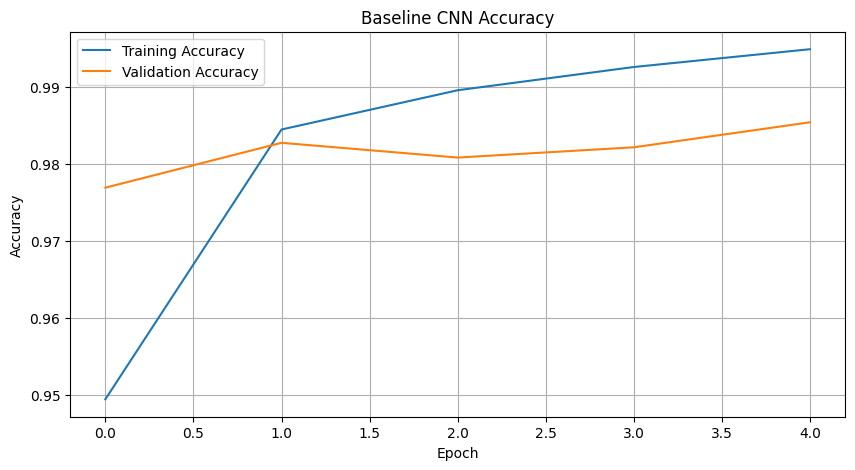

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    baseline_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

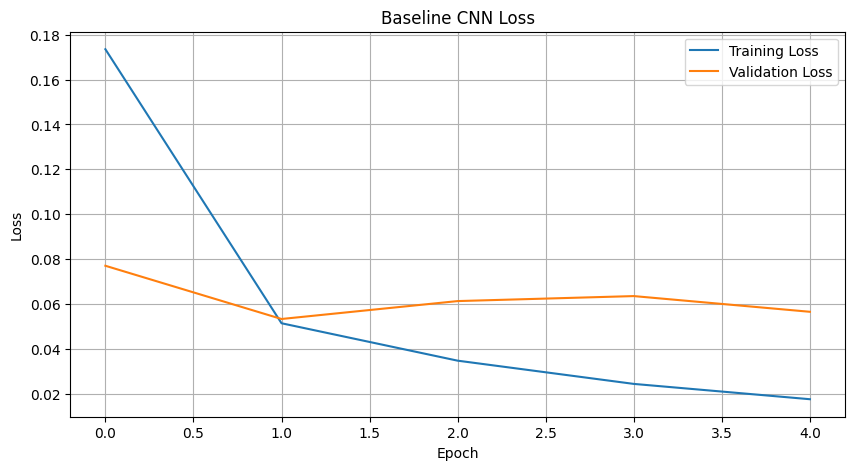

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

**Baseline Training Interpretation:**

The accuracy and loss curves are used to assess the model's learning behaviour.

Training accuracy measures performance on images used to update the model, while validation accuracy measures performance on unseen validation images.

The curves help identify whether the model is learning effectively and whether overfitting may be occurring.

## Section 8: Improved CNN model
## 10. Developing the Improved CNN Model

An improved CNN will be developed to investigate whether data augmentation and dropout can improve generalisation.

Data augmentation introduces small variations in training images, while dropout reduces reliance on individual neurons an

**Improved CNN Architecture**

The improved model includes:
- Random rotation and translation for data augmentation.
- Convolutional layers for feature extraction.
- Max pooling to reduce spatial dimensions.
- A larger dense layer to learn more complex feature relationships.
- Dropout to reduce overfitting.
- Softmax output for ten-class classification.

The augmentation layers are active during training and do not modify the validation or test images.

In [24]:
improved_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),

    keras.layers.RandomRotation(0.05),
    keras.layers.RandomTranslation(0.05, 0.05),

    keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        name="improved_conv1"
    ),

    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        name="improved_conv2"
    ),

    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),

    keras.layers.Dropout(0.4),

    keras.layers.Dense(10, activation="softmax")
])

print("Improved CNN model created successfully!")

Improved CNN model created successfully!


**Examining the Improved Model**

The model summary is examined to understand the number of layers, output dimensions, and trainable parameters.

In [25]:
improved_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_rotation (RandomRotation)     │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_translation                   │ (None, 28, 28, 1)           │               0 │
│ (RandomTranslation)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ improved_conv1 (Conv2D)              │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ improved_conv2 (Conv2D)              │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

**Compiling the Improved Model**

The improved model uses the Adam optimiser, sparse categorical cross-entropy loss, and accuracy metric.

The learning rate remains at 0.001 to maintain a consistent starting point for comparison with the baseline model.

In [26]:
improved_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved model compiled successfully!")

Improved model compiled successfully!


**Training the Improved Model**

The improved model will be trained for up to 15 epochs with a batch size of 64.

Early stopping monitors validation loss and restores the best weights. This helps prevent unnecessary training when validation performance stops improving.

In [29]:
improved_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    x_train_final,
    y_train_final,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[improved_early_stopping],
    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.9798 - loss: 0.0673 - val_accuracy: 0.9869 - val_loss: 0.0458
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 69s 56ms/step - accuracy: 0.9821 - loss: 0.0607 - val_accuracy: 0.9897 - val_loss: 0.0401
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 59ms/step - accuracy: 0.9822 - loss: 0.0574 - val_accuracy: 0.9893 - val_loss: 0.0376
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 59ms/step - accuracy: 0.9837 - loss: 0.0542 - val_accuracy: 0.9911 - val_loss: 0.0342
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 58ms/step - accuracy: 0.9849 - loss: 0.0487 - val_accuracy: 0.9906 - val_loss: 0.0357
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9856 - loss: 0.0473 - val_accuracy: 0.9925 - val_loss: 0.0305
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 66ms/step - accuracy: 0.9867 - loss: 0.0459 - val_accuracy: 0.9919 - val_loss: 0.0327
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 46s 62ms/step - accuracy: 0.9868 - loss: 0.0445 - 

**Improved Model Accuracy**

Training and validation accuracy are plotted to examine whether the improved model learns effectively and generalises to unseen validation images.

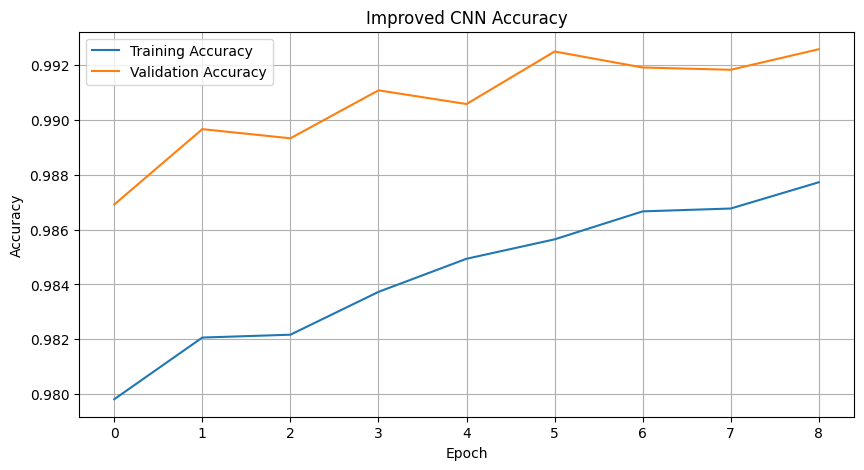

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    improved_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    improved_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Improved CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

**Improved Model Training Interpretation:**

The training curves show how the improved model performs across the epochs.

The validation results are particularly important because they indicate how well the model performs on images that were not used to update its weights.

## Section 9: Model comparison and feature-map analysis
## 11. Comparing the CNN Models

The baseline and improved models will be compared using validation accuracy and validation loss.

The model with the strongest validation performance will be selected for final testing. The test dataset will not be us

In [31]:
baseline_val_loss, baseline_val_accuracy = baseline_model.evaluate(
    x_val, y_val, verbose=0
)

improved_val_loss, improved_val_accuracy = improved_model.evaluate(
    x_val, y_val, verbose=0
)

comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Validation Accuracy": [
        baseline_val_accuracy,
        improved_val_accuracy
    ],
    "Validation Loss": [
        baseline_val_loss,
        improved_val_loss
    ]
})

display(comparison.round(4))

,Model,Validation Accuracy,Validation Loss
0,Baseline CNN,0.9827,0.0532
1,Improved CNN,0.9925,0.0305


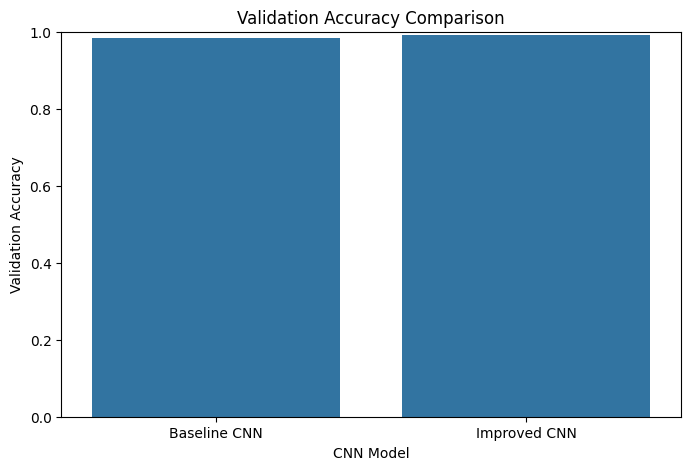

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Validation Accuracy"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("CNN Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.show()

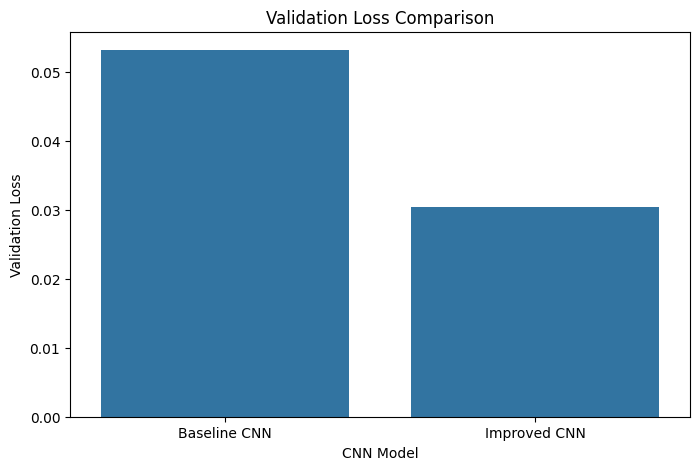

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Validation Loss"
)

plt.title("Validation Loss Comparison")
plt.xlabel("CNN Model")
plt.ylabel("Validation Loss")
plt.show()

In [34]:
if improved_val_accuracy > baseline_val_accuracy:
    best_model = improved_model
    best_model_name = "Improved CNN"

elif baseline_val_accuracy > improved_val_accuracy:
    best_model = baseline_model
    best_model_name = "Baseline CNN"

else:
    if improved_val_loss < baseline_val_loss:
        best_model = improved_model
        best_model_name = "Improved CNN"
    else:
        best_model = baseline_model
        best_model_name = "Baseline CNN"

print("Selected model:", best_model_name)
print("Baseline validation accuracy:",
      round(baseline_val_accuracy, 4))

print("Improved validation accuracy:",
      round(improved_val_accuracy, 4))

print("Baseline validation loss:",
      round(baseline_val_loss, 4))

print("Improved validation loss:",
      round(improved_val_loss, 4))

Selected model: Improved CNN
Baseline validation accuracy: 0.9827
Improved validation accuracy: 0.9925
Baseline validation loss: 0.0532
Improved validation loss: 0.0305


**Model Comparison Interpretation**

The comparison identifies which model achieved the strongest validation performance.

A higher validation accuracy indicates that more validation images were classified correctly. A lower validation loss indicates better alignment between predicted probabilities and the actual labels.

The selected model is based on validation results rather than test performance. The improved model is not automatically assumed to be better; the actual results determine the selection.

**Visualising CNN Feature Maps**

Convolutional layers learn visual features from images. Earlier layers may respond to simple patterns such as edges and curves, while deeper layers can combine these patterns into more complex representations.

Feature maps from the first convolutional layer will be visualised to examine what the selected CNN learns from an image.

In [35]:
conv_layers = [
    layer for layer in best_model.layers
    if isinstance(layer, keras.layers.Conv2D)
]

print("Number of convolutional layers:", len(conv_layers))

feature_extractor = keras.Model(
    inputs=best_model.inputs,
    outputs=conv_layers[0].output
)

sample_for_features = x_test_cnn[:1]

feature_maps = feature_extractor.predict(
    sample_for_features,
    verbose=0
)

print("Feature map shape:", feature_maps.shape)

Number of convolutional layers: 2
Feature map shape: (1, 26, 26, 32)


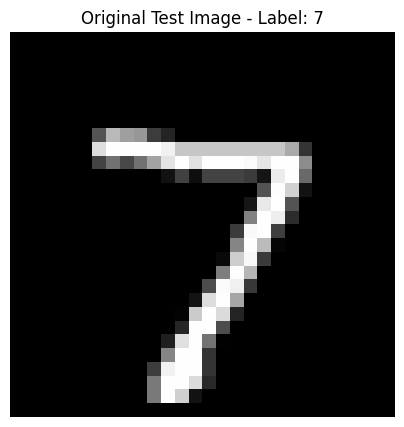

In [37]:
plt.figure(figsize=(5, 5))

plt.imshow(x_test_cnn[0].squeeze(), cmap="gray")
plt.title(f"Original Test Image - Label: {y_test[0]}")
plt.axis("off")
plt.show()

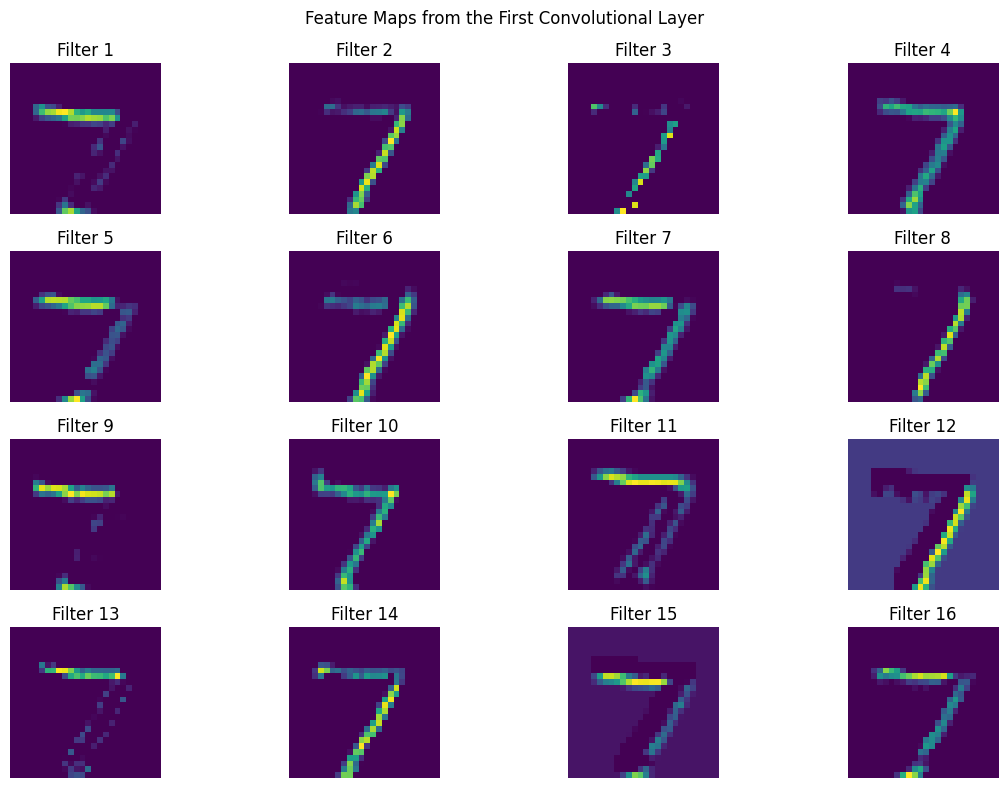

In [38]:
number_of_maps = min(16, feature_maps.shape[-1])

plt.figure(figsize=(12, 8))

for i in range(number_of_maps):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title(f"Filter {i + 1}")
    plt.axis("off")

plt.suptitle("Feature Maps from the First Convolutional Layer")
plt.tight_layout()
plt.show()

**Feature Map Interpretation:**

The feature maps demonstrate how convolutional filters transform the original image into learned visual representations.

Different filters respond to different patterns within the image. These learned representations are passed through later CNN layers to support digit classification.

The visualisations provide evidence that the CNN learns image features rather than relying only on the original image labels.

## Section 10: Final model evaluation
## 12. Final Evaluation Using the Test Dataset

The selected model will now be evaluated using the separate test dataset.

This provides an estimate of how well the model performs on images that were not used during training, validation, or model

In [39]:
test_loss, test_accuracy = best_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

print("\nFinal Model:", best_model_name)
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy Percentage:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9935 - loss: 0.0189

Final Model: Improved CNN
Test Accuracy: 0.9935
Test Loss: 0.0189
Test Accuracy Percentage: 99.35 %


**Generating Predictions**

The selected model produces probability values for each of the ten digit classes.

The class with the highest predicted probability is selected as the final prediction.

In [40]:
y_pred_probabilities = best_model.predict(
    x_test_cnn,
    verbose=1
)

y_pred = np.argmax(y_pred_probabilities, axis=1)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
Predictions generated successfully!
Number of predictions: 10000


**Comparing Actual and Predicted Digits**

A sample of test images is displayed alongside their actual and predicted labels. This provides a visual assessment of the model's classification ability.

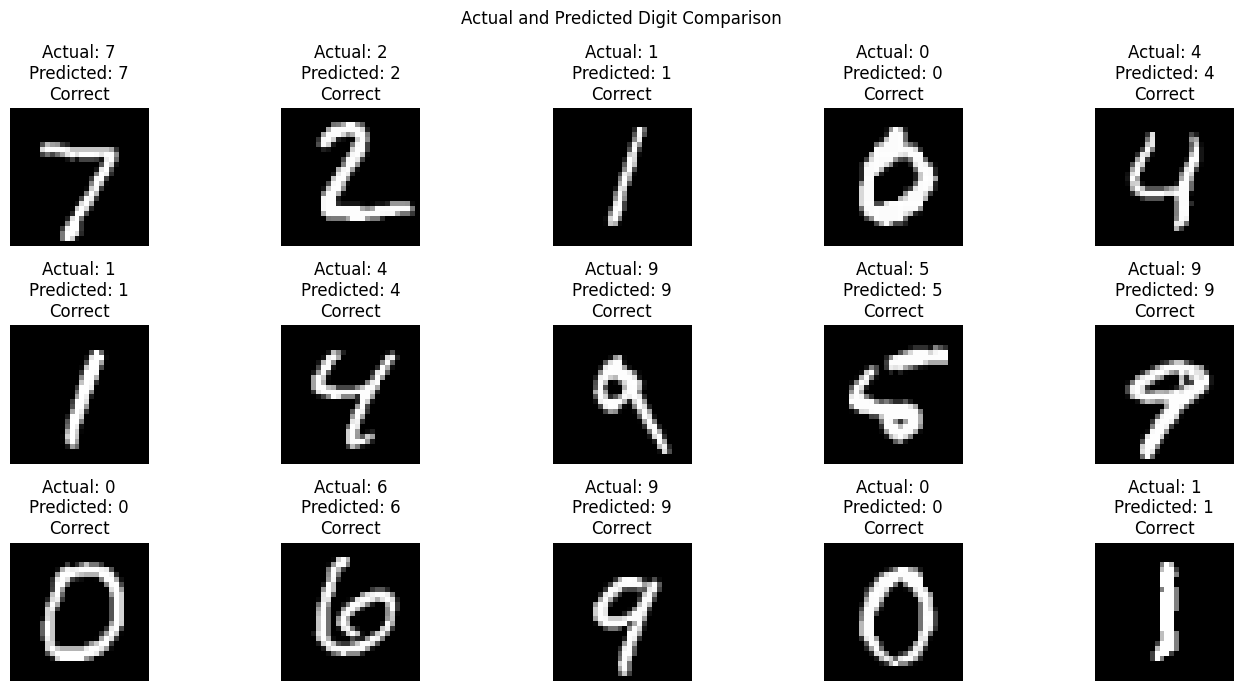

In [41]:
plt.figure(figsize=(14, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_test_cnn[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = y_pred[i]

    result = "Correct" if actual == predicted else "Incorrect"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\n{result}"
    )

    plt.axis("off")

plt.suptitle("Actual and Predicted Digit Comparison")
plt.tight_layout()
plt.show()

**Classification Report**

The classification report provides precision, recall, F1-score, and support for each digit class.

These metrics provide a more detailed evaluation than accuracy alone.

In [42]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=range(10),
        target_names=[str(i) for i in range(10)],
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       1.00      0.99      1.00       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00      1.00       982
           5       1.00      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      1.00      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



**Confusion Matrix**

A confusion matrix shows how many images from each actual digit class were correctly or incorrectly classified.

Correct predictions appear along the main diagonal, while incorrect predictions appear outside the diagonal.

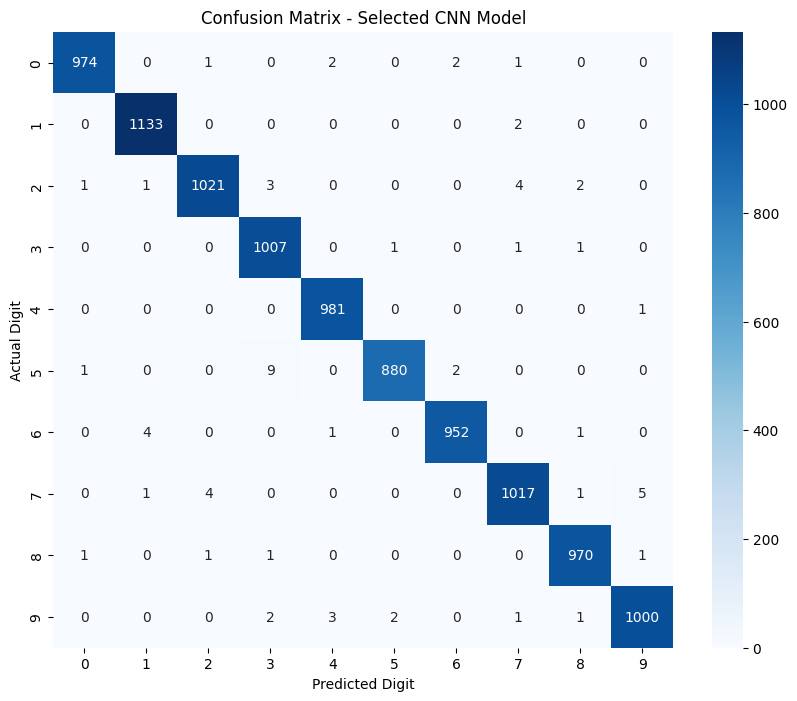

In [43]:
cm = confusion_matrix(y_test, y_pred, labels=range(10))

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix - Selected CNN Model")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

**Confusion Matrix Interpretation:**

The main diagonal represents correctly classified images. Values outside the diagonal represent misclassifications.

The largest off-diagonal values identify pairs of digits that the model finds difficult to distinguish. These errors may result from similarities in handwriting, digit shape, or stroke patterns.

**Identifying Incorrect Predictions**

Incorrectly classified images will be examined to understand the types of patterns that may cause the CNN to make mistakes.

In [44]:
incorrect_indices = np.where(y_pred != y_test)[0]

print("Total incorrect predictions:", len(incorrect_indices))
print("Total correct predictions:", len(y_test) - len(incorrect_indices))

print(
    "Error rate:",
    round((len(incorrect_indices) / len(y_test)) * 100, 2),
    "%"
)

Total incorrect predictions: 65
Total correct predictions: 9935
Error rate: 0.65 %


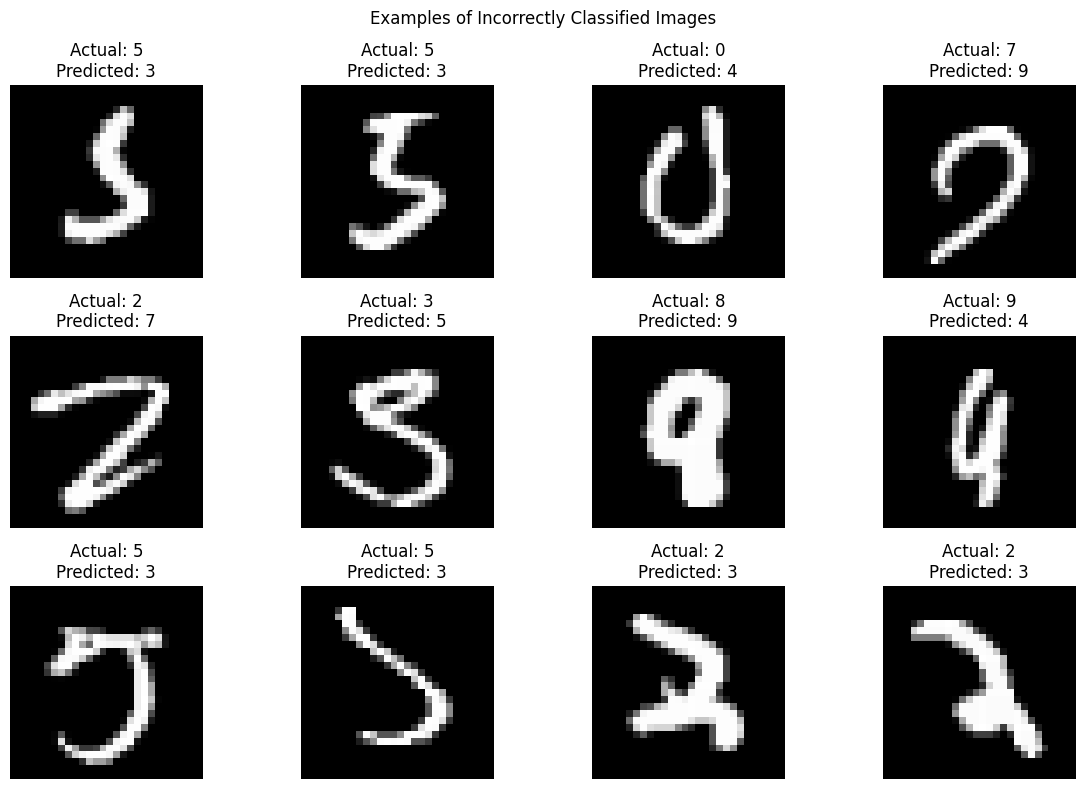

In [45]:
number_to_display = min(12, len(incorrect_indices))

plt.figure(figsize=(12, 8))

for i in range(number_to_display):
    index = incorrect_indices[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test_cnn[index].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {y_pred[index]}"
    )

    plt.axis("off")

plt.suptitle("Examples of Incorrectly Classified Images")
plt.tight_layout()
plt.show()

**Error Analysis Interpretation:**

Incorrect predictions provide insight into the limitations of the model.

Some handwritten digits may share similar shapes or contain unusual writing styles. Examining these errors helps identify where the model may struggle and where future improvements could be made.

## Section 11: Additional performance analysis
## 13. Additional Performance Analysis

Further analysis is conducted to examine the distribution of classification errors and the confidence of the model's p

In [46]:
class_accuracy = []

for digit in range(10):
    digit_indices = np.where(y_test == digit)[0]

    correct_predictions = np.sum(
        y_pred[digit_indices] == y_test[digit_indices]
    )

    accuracy = correct_predictions / len(digit_indices)

    class_accuracy.append(accuracy)

class_performance = pd.DataFrame({
    "Digit": range(10),
    "Accuracy": class_accuracy,
    "Accuracy Percentage": np.array(class_accuracy) * 100
})

display(class_performance.round(4))

,Digit,Accuracy,Accuracy Percentage
0,0,0.9939,99.3878
1,1,0.9982,99.8238
2,2,0.9893,98.9341
3,3,0.9970,99.7030
4,4,0.9990,99.8982
5,5,0.9865,98.6547
6,6,0.9937,99.3737
7,7,0.9893,98.9300
8,8,0.9959,99.5893
9,9,0.9911,99.1080


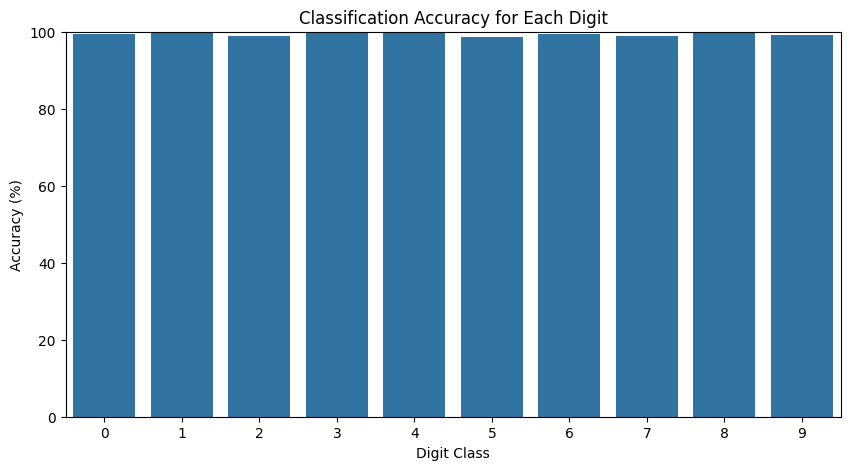

In [47]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_performance,
    x="Digit",
    y="Accuracy Percentage"
)

plt.title("Classification Accuracy for Each Digit")
plt.xlabel("Digit Class")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

**Class-Specific Performance Interpretation:**

The class-specific accuracy results show whether the model performs consistently across all ten digits.

Differences between classes may indicate that certain handwritten patterns are more difficult to recognise. This information can guide future improvements to the model and dataset.

**Prediction Confidence**

The model's maximum predicted probability is used as an indication of its confidence in each classification.

A high confidence score does not guarantee that a prediction is correct, but it helps identify predictions where the model appears uncertain.

Average prediction confidence: 0.9959
Minimum prediction confidence: 0.4243
Maximum prediction confidence: 1.0


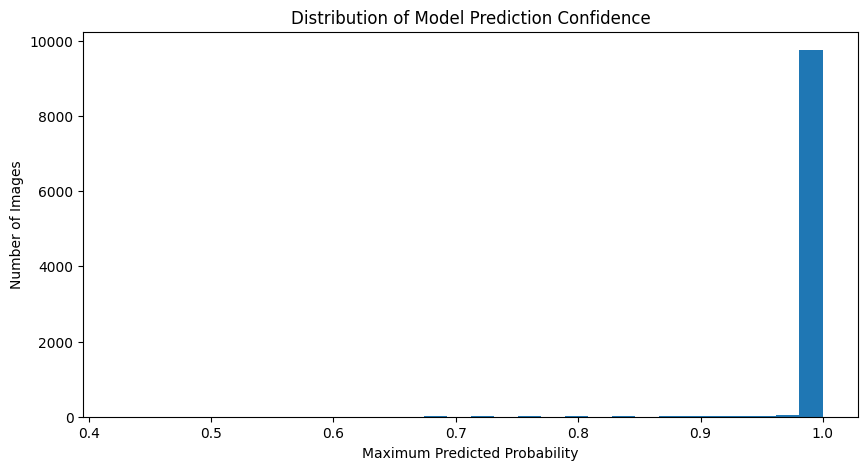

In [48]:
prediction_confidence = np.max(
    y_pred_probabilities,
    axis=1
)

print(
    "Average prediction confidence:",
    round(prediction_confidence.mean(), 4)
)

print(
    "Minimum prediction confidence:",
    round(prediction_confidence.min(), 4)
)

print(
    "Maximum prediction confidence:",
    round(prediction_confidence.max(), 4)
)

plt.figure(figsize=(10, 5))

plt.hist(prediction_confidence, bins=30)

plt.title("Distribution of Model Prediction Confidence")
plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Images")
plt.show()

**Prediction Confidence Interpretation:**

The confidence distribution indicates how strongly the model favours its predicted classes.

Low-confidence predictions may occur when an image contains unusual handwriting or visual patterns that resemble multiple digits. Confidence should be interpreted alongside classification accuracy because a model can sometimes be confidently incorrect.

## Section 12: Saving the selected model
## 14. Saving the Selected CNN Model

The selected model is saved so that it can be loaded and used for future predictions without repeating the training process.

In [49]:
model_filename = "final_mnist_cnn_model.keras"

best_model.save(model_filename)


print("Model saved successfully as:", model_filename)

Model saved successfully as: final_mnist_cnn_model.keras


**Loading the Saved Model**

The saved model is loaded to confirm that it can be reused.

In [50]:
loaded_model = keras.models.load_model(model_filename)

print("Saved model loaded successfully!")

loaded_model.summary()

Saved model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_rotation (RandomRotation)     │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_translation                   │ (None, 28, 28, 1)           │               0 │
│ (RandomTranslation)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ improved_conv1 (Conv2D)              │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ improved_conv2 (Conv2D)              │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 675,104 (2.58 MB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 450,070 (1.72 MB)

In [51]:
loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

print("Original selected model accuracy:", round(test_accuracy, 4))
print("Loaded model accuracy:", round(loaded_accuracy, 4))

print(
    "Accuracy preserved:",
    np.isclose(test_accuracy, loaded_accuracy, atol=1e-5)
)

Original selected model accuracy: 0.9935
Loaded model accuracy: 0.9935
Accuracy preserved: True


## Section 13: Limitations, recommendations and conclusion
## 15. Project Limitations

Although the MNIST dataset is useful for demonstrating CNN-based image recognition, the project has several limitations:

1. The dataset contains handwritten digits rather than human faces.
2. Images have a consistent size and grayscale format, unlike many real-world images.
3. The model has only been evaluated on the MNIST test dataset.
4. Performance on other image datasets has not been established.
5. The model is not suitable for identifying or verifying individuals.

These limitations should be considered before applying the approach to a different image recognition problem.

## 16. Recommendations for Future Development

Future development could include:

- Training a CNN using a suitable facial image dataset.
- Obtaining appropriate consent for the collection and use of facial images.
- Protecting personal information through secure storage and controlled access.
- Testing performance across different lighting conditions, facial angles, and image qualities.
- Evaluating model bias and differences in performance across relevant groups.
- Investigating more advanced CNN architectures and regularisation techniques.
- Testing the system on an independent dataset before considering real-world deployment.

A facial recognition system would require additional technical, ethical, privacy, and security considerations beyond those demonstrated by MNIST.

## 17. Conclusion

This project investigated the use of Convolutional Neural Networks for image recognition using the MNIST handwritten digits dataset.

The analysis included dataset inspection, exploratory data analysis, image preprocessing, feature extraction, CNN development, model comparison, and final evaluation.

Two CNN models were developed and compared using validation performance. The selected model was then evaluated on the separate test dataset using accuracy, precision, recall, F1-score, a confusion matrix, and prediction error analysis.

The project demonstrates how CNNs can learn visual patterns from image data and use these patterns to classify images. However, the results apply specifically to handwritten digit recognition and should not be interpreted as evidence of facial recognition capability.

Overall, the project provides a foundation for understanding CNN-based image recognition and the additional considerations required when developing more complex real-world systems.